# YYZ Revenue Runway: 01 Clean and explore (Phase 2)

**Business question:** Is Toronto Pearson's revenue growth coming from more travellers, or from charging each traveller more?

This notebook owns what only Python does well in the pipeline:

1. Attach the **published fee rates** to every quarter (from the GTAA fee schedules)
2. Convert dollars to **2019 dollars** with Ontario CPI, so prices can be compared over time
3. Build the **per-unit KPIs for each quarter** (per passenger, per flight, per tonne)
4. Export a clean, Supabase-ready table

Anything that compares one quarter with another (year-over-year, vs 2019, revenue bridge, trailing 12 months) is deliberately left for **Phase 3 in SQL**, where window functions do it best.

Inputs come from Phase 1 (`scripts/00`–`04`), every value traced to its GTAA report page.

In [1]:
# Works locally (run from the repo root or notebooks/) and in Google Colab
import os, sys
from pathlib import Path
if 'google.colab' in sys.modules and not Path('yyz-revenue-runway').exists():
    !git clone -q https://github.com/ShubhamSarje/yyz-revenue-runway
    os.chdir('yyz-revenue-runway')
BASE = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
PROC = BASE / 'data' / 'processed'
FIG = BASE / 'assets'
FIG.mkdir(exist_ok=True)

import pandas as pd, numpy as np
import matplotlib.pyplot as plt
pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 40)

## 1. Load the Phase 1 outputs

In [2]:
q   = pd.read_csv(PROC / 'yyz_quarterly.csv')                # 35 quarters, GTAA reports
fee = pd.read_csv(PROC / 'fee_rates.csv', parse_dates=['effective_date'])
chg = pd.read_csv(PROC / 'fee_changes_mdna.csv')              # % change in aeronautical fees each January
cpi = pd.read_csv(PROC / 'cpi_ontario_quarterly.csv')
sc  = pd.read_csv(PROC / 'statcan_movements_quarterly.csv')

print(q.shape, q.period.min(), '->', q.period.max())
q[['period','revenue_total','aero_revenue','commercial_revenue','aif_revenue','pax_total','movements','ebitda']].tail()

(35, 37) 2018Q1 -> 2026Q3


,period,revenue_total,aero_revenue,commercial_revenue,aif_revenue,pax_total,movements,ebitda
30,2025Q3,562.2,190.1,176.3,195.8,13.1,104.6,291.5
31,2025Q4,514.6,170.4,165.0,179.2,11.5,97.1,220.9
32,2026Q1,522.4,181.2,164.5,176.7,11.1,92.8,239.3
33,2026Q2,566.6,196.5,174.1,196.0,12.4,101.2,277.2
34,2026Q3,626.5,209.2,194.1,223.2,13.8,106.7,327.5


## 2. Clean

- A real date for each quarter (`period_start`) so rates can be matched by date
- Flags: COVID quarters (2020–2021) are kept but excluded from averages later; CPE is only published from 2023
- Q1 2022 is flagged too: the Omicron wave kept traffic low while fixed revenue (rentals, concessions) continued, so per-passenger figures spike that quarter
- Q4 2020 ground rent is negative: the federal government's COVID rent relief was booked as a credit that quarter. It is kept as reported and flagged

In [3]:
q['period_start'] = pd.PeriodIndex(q.period, freq='Q').start_time
q = q.sort_values('period_start').reset_index(drop=True)
q['covid_period'] = q.year.isin([2020, 2021])
q['omicron_flag'] = q.period.eq('2022Q1')
q['ground_rent_relief_flag'] = q.ground_rent < 0
q['cpe_available'] = q.cpe.notna()

# basic integrity: one row per quarter, no gaps
assert q.period.is_unique and len(q) == 35
assert (pd.PeriodIndex(q.period, freq='Q').asi8[1:] - pd.PeriodIndex(q.period, freq='Q').asi8[:-1] == 1).all()
q[['period','covid_period','ground_rent','ground_rent_relief_flag','cpe']].iloc[[0, 9, 11, 20, 34]]

,period,covid_period,ground_rent,ground_rent_relief_flag,cpe
0,2018Q1,False,39.2,False,NaN
9,2020Q2,True,8.9,False,NaN
11,2020Q4,True,-9.6,True,NaN
20,2023Q1,False,47.8,False,30.5
34,2026Q3,False,70.8,False,31.4


## 3. Attach the published fee rates

Each quarter gets the rates in force on its first day (`merge_asof` = "latest schedule on or before this date").
The **aeronautical rate index** (2019 = 100) compounds the January % changes the GTAA states in its MD&A.

In [4]:
fee = fee.sort_values('effective_date')
q = pd.merge_asof(q, fee.drop(columns='source'), left_on='period_start', right_on='effective_date')

chg = chg.sort_values('year')
chg['aero_rate_index'] = (1 + chg.pct / 100).cumprod()
chg['aero_rate_index'] = chg.aero_rate_index / chg.loc[chg.year == 2019, 'aero_rate_index'].iloc[0] * 100
q = q.merge(chg[['year', 'aero_rate_index']], on='year', how='left')

q.groupby('year')[['gtc_domestic_per_seat','landing_per_1000kg','aif_local','aif_connecting','aero_rate_index']].first().round(2)

,gtc_domestic_per_seat,landing_per_1000kg,aif_local,aif_connecting,aero_rate_index
year,,,,,
2018,7.06,17.19,25.0,4.0,100.00
2019,7.06,17.19,25.0,4.0,100.00
2020,7.06,17.19,25.0,4.0,100.00
2021,7.27,17.71,30.0,6.0,103.00
2022,7.49,18.24,30.0,6.0,106.09
2023,7.79,18.97,35.0,7.0,110.33
2024,8.18,18.97,35.0,7.0,114.75
2025,8.59,19.92,37.0,8.0,120.48
2026,9.03,20.94,40.0,10.0,126.63


**Reading it:** rates were frozen from 2018 to 2020, then rose every January from 2021. The local improvement fee went from \$25 to \$40 (+60%) and the connecting fee from \$4 to \$10, while the aeronautical rate index rose about 27% by 2026.

## 4. Inflation: 2019 dollars

Deflator = quarter's Ontario CPI ÷ average 2019 CPI. A "real" value is the nominal value divided by the deflator.

In [5]:
cpi_2019 = cpi.loc[cpi.period.str.startswith('2019'), 'cpi_ontario'].mean()
q = q.merge(cpi[['period', 'cpi_ontario']], on='period', how='left')
q['deflator_2019'] = q.cpi_ontario / cpi_2019
assert q.deflator_2019.notna().all()
q[['period','cpi_ontario','deflator_2019']].iloc[[4, 24, 34]].round(3)

,period,cpi_ontario,deflator_2019
4,2019Q1,136.07,0.990
24,2024Q1,160.50,1.167
34,2026Q3,170.07,1.237


## 5. Per-unit KPIs for each quarter

Airports measure price and cost **per enplaned passenger** (a passenger boarding at the airport). The GTAA defines enplaned passengers as half of total passengers.

| KPI | Formula |
|---|---|
| Revenue / aero / commercial / AIF per enplaned passenger | revenue line ($M) ÷ enplaned passengers (M) |
| AIF yield ratio | AIF per enplaned passenger ÷ local AIF rate |
| Implied connecting share (estimate) | (local rate − AIF yield) ÷ (local rate − connecting rate) |
| Operating cost per enplaned passenger | opex before amortization ÷ enplaned passengers |
| Ground rent share | ground rent ÷ total revenue |
| Seats / passengers / MTOW per movement | ÷ aircraft movements |
| Aeronautical revenue per tonne MTOW | aero revenue ÷ MTOW |
| Real (2019 $) versions | nominal ÷ deflator |

In [6]:
E = q.pax_total / 2                                    # enplaned passengers, millions
q['enplaned_pax'] = E.round(2)

q['revenue_per_enplaned']    = q.revenue_total / E
q['aero_per_enplaned']       = q.aero_revenue / E
q['commercial_per_enplaned'] = q.commercial_revenue / E
q['parking_per_enplaned']    = q.parking_ground / E
q['aif_per_enplaned']        = q.aif_revenue / E
q['opex_per_enplaned']       = q.opex_before_amort / E

q['aif_yield_ratio']          = q.aif_per_enplaned / q.aif_local
q['implied_connecting_share'] = (q.aif_local - q.aif_per_enplaned) / (q.aif_local - q.aif_connecting)

q['ground_rent_share_pct']   = q.ground_rent / q.revenue_total * 100
q['aero_share_pct']          = q.aero_revenue / q.revenue_total * 100
q['commercial_share_pct']    = q.commercial_revenue / q.revenue_total * 100
q['aif_share_pct']           = q.aif_revenue / q.revenue_total * 100

q['seats_per_movement']      = q.seats / q.movements * 1000          # seats (m) / movements (k)
q['pax_per_movement']        = q.pax_total / q.movements * 1000
q['mtow_tonnes_per_movement']= q.mtow / q.movements * 1000
q['aero_per_tonne_mtow']     = q.aero_revenue / q.mtow                # $ per tonne
q['opex_per_movement_k']     = q.opex_before_amort / q.movements      # $ thousands per movement

for c in ['revenue_per_enplaned','aero_per_enplaned','commercial_per_enplaned','aif_per_enplaned',
          'opex_per_enplaned','aero_per_tonne_mtow','cpe']:
    q[c + '_real2019'] = q[c] / q.deflator_2019

q = q.merge(sc[['period','transborder','total_itinerant','transborder_share','complete_quarter']]
              .rename(columns={'transborder':'transborder_movements','total_itinerant':'itinerant_movements',
                               'transborder_share':'transborder_share_pct','complete_quarter':'statcan_complete_quarter'}),
            on='period', how='left')

q[['period','revenue_per_enplaned','revenue_per_enplaned_real2019','aif_yield_ratio','seats_per_movement',
   'ground_rent_share_pct','transborder_share_pct']].iloc[[4,5,6,7,28,29,30,31,34]].round(2)

,period,revenue_per_enplaned,revenue_per_enplaned_real2019,aif_yield_ratio,seats_per_movement,ground_rent_share_pct,transborder_share_pct
4,2019Q1,61.95,62.60,0.75,132.46,11.29,39.5
5,2019Q2,57.95,57.81,0.70,130.89,11.22,40.4
6,2019Q3,56.77,56.46,0.72,134.21,11.19,37.9
7,2019Q4,64.69,64.54,0.66,132.60,11.25,40.5
28,2025Q1,91.10,76.33,0.81,145.67,11.30,41.0
29,2025Q2,86.78,72.07,0.81,145.58,11.31,39.7
30,2025Q3,85.83,71.01,0.81,147.23,11.33,36.0
31,2025Q4,89.50,73.96,0.84,143.15,11.35,38.4
34,2026Q3,90.80,73.40,0.81,149.95,11.30,34.4


**A caution on the implied connecting share.** Airlines keep an administration fee for collecting the AIF, and some passengers are exempt, so AIF revenue per passenger sits below what the rates alone imply. That makes this estimate biased, and the bias may change over time. It stays in the data **flagged as an estimate**, and Phase 4 tests the hub-paradox idea against the GTAA's own wording instead of relying on it.

## 6. Sanity checks

In [7]:
normal = q[~q.covid_period & ~q.omicron_flag]
print('Q1 2022 (Omicron) revenue per enplaned pax:', round(q.loc[q.omicron_flag, 'revenue_per_enplaned'].iloc[0], 2))
checks = {
    'revenue per enplaned pax between $50 and $100 outside COVID and Omicron': normal.revenue_per_enplaned.between(50, 100).all(),
    'AIF yield below the local rate in every quarter':                (q.aif_per_enplaned < q.aif_local).all(),
    'revenue shares add to 100%':                                     np.allclose(q.aero_share_pct + q.commercial_share_pct + q.aif_share_pct, 100, atol=0.2),
    'load factor between 0 and 100':                                  q.load_factor.between(0, 100).all(),
    'deflator rises over time':                                       q.deflator_2019.iloc[-1] > q.deflator_2019.iloc[0],
    'seats per movement 100-170':                                     q.seats_per_movement.between(100, 170).all(),
}
for k, v in checks.items():
    print(('PASS ' if v else 'FAIL ') + k)
assert all(checks.values())

Q1 2022 (Omicron) revenue per enplaned pax: 108.73
PASS revenue per enplaned pax between $50 and $100 outside COVID and Omicron
PASS AIF yield below the local rate in every quarter
PASS revenue shares add to 100%
PASS load factor between 0 and 100
PASS deflator rises over time
PASS seats per movement 100-170


## 7. First look

Annual figures, COVID years shown but read separately.

In [8]:
a = q.groupby('year').agg(revenue=('revenue_total','sum'), pax=('pax_total','sum'),
                          deflator=('deflator_2019','mean'), quarters=('period','count'))
a['revenue_per_enplaned'] = a.revenue / (a.pax / 2)
a['revenue_per_enplaned_real2019'] = a.revenue_per_enplaned / a.deflator
a.round(2)

,revenue,pax,deflator,quarters,revenue_per_enplaned,revenue_per_enplaned_real2019
year,,,,,,
2018,1471.8,49.4,0.98,4,59.59,60.70
2019,1521.3,50.6,1.00,4,60.13,60.13
2020,823.5,13.3,1.01,4,123.83,123.05
2021,826.8,12.7,1.04,4,130.20,125.04
2022,1491.8,35.6,1.11,4,83.81,75.36
2023,1887.2,44.9,1.15,4,84.06,72.83
2024,1975.4,46.7,1.18,4,84.60,71.59
2025,2084.9,47.3,1.20,4,88.16,73.21
2026,1715.5,37.3,1.23,3,91.98,74.92


In [9]:
BLUE, ORANGE, INK, MUTED, GRID = '#2a78d6', '#eb6834', '#1f1f1e', '#6b6a63', '#e4e3df'
def style(ax, title, subtitle):
    ax.set_title(title, loc='left', fontsize=13, fontweight='bold', color=INK, pad=22)
    ax.text(0, 1.02, subtitle, transform=ax.transAxes, fontsize=9.5, color=MUTED)
    for s in ['top', 'right']: ax.spines[s].set_visible(False)
    for s in ['left', 'bottom']: ax.spines[s].set_color(GRID)
    ax.tick_params(colors=MUTED, labelsize=9)
    ax.grid(axis='y', color=GRID, linewidth=0.8); ax.set_axisbelow(True)
def covid_band(ax, x):
    i0, i1 = list(x).index('2020Q2'), list(x).index('2021Q4')
    ax.axvspan(i0 - 0.5, i1 + 0.5, color=GRID, alpha=0.6, linewidth=0)
    ax.text((i0 + i1) / 2, ax.get_ylim()[1] * 0.97, 'COVID (excluded)', ha='center', va='top', fontsize=8.5, color=MUTED)

x = list(q.period); idx = range(len(x)); ticks = [i for i, p in enumerate(x) if p.endswith('Q1')]

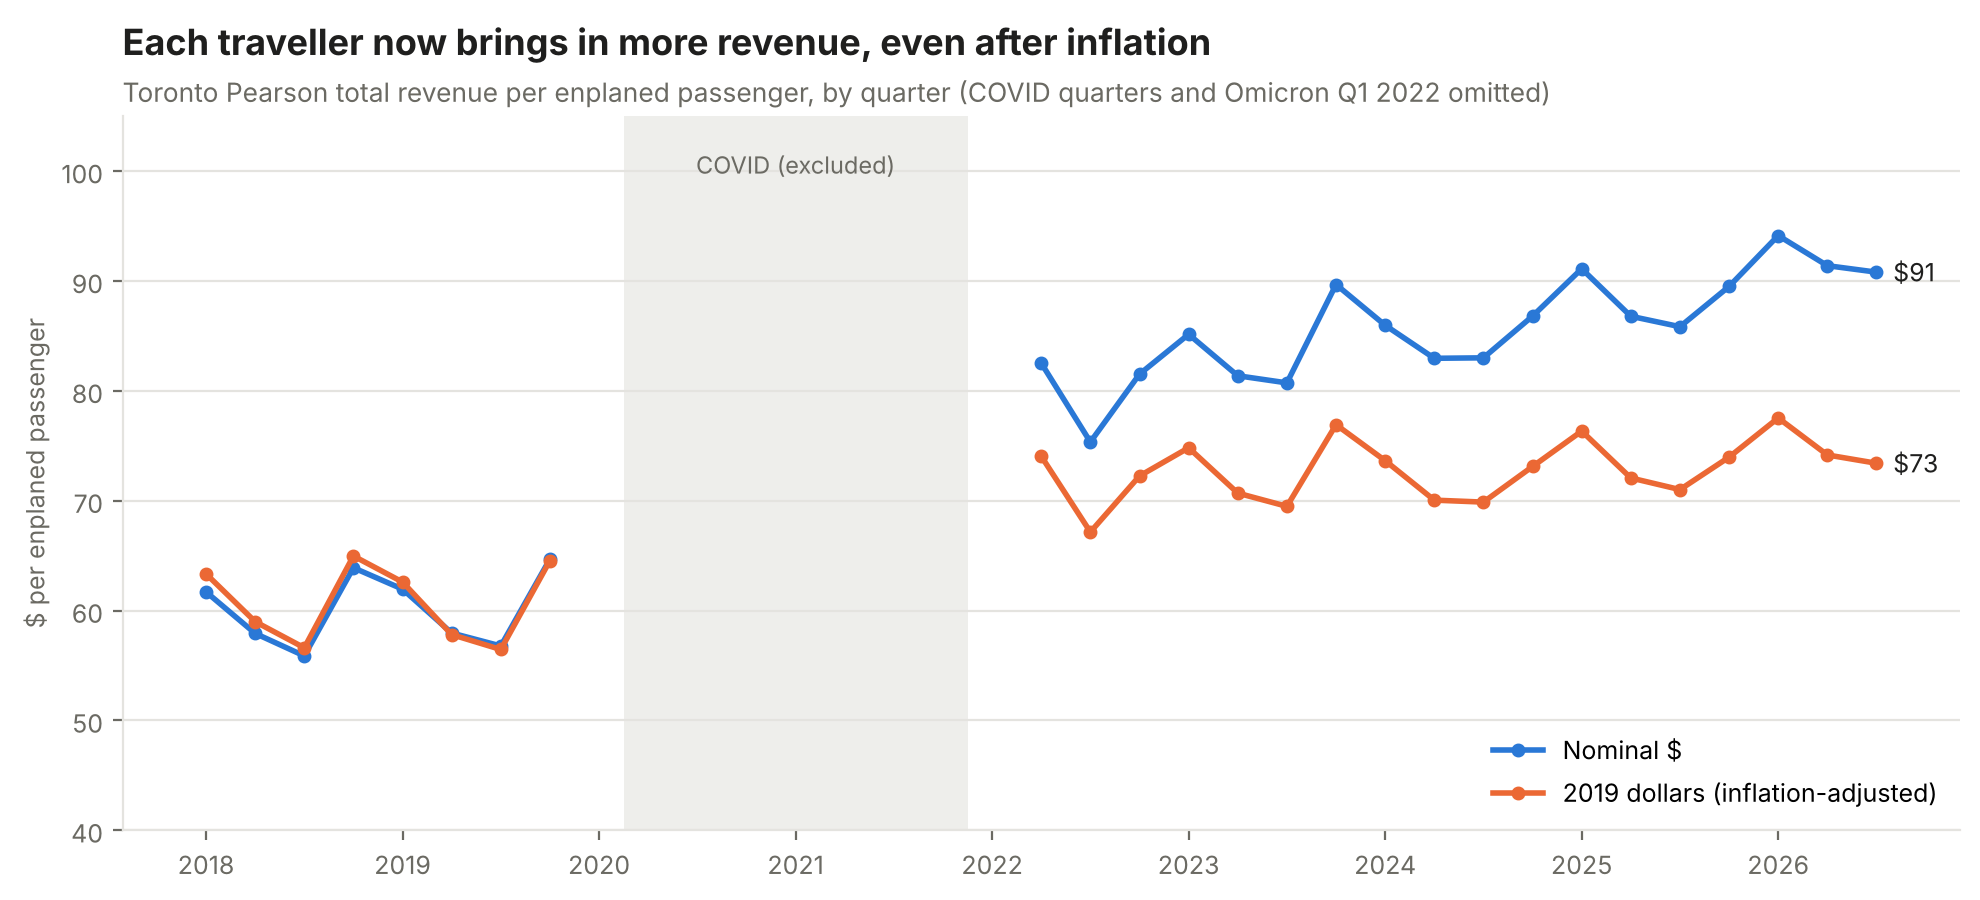

In [10]:
fig, ax = plt.subplots(figsize=(10, 4.6))
nominal = q.revenue_per_enplaned.where(~q.covid_period & ~q.omicron_flag)
real = q.revenue_per_enplaned_real2019.where(~q.covid_period & ~q.omicron_flag)
ax.plot(idx, nominal, color=BLUE, lw=2, marker='o', ms=4, label='Nominal $')
ax.plot(idx, real, color=ORANGE, lw=2, marker='o', ms=4, label='2019 dollars (inflation-adjusted)')
ax.set_ylim(40, 105); covid_band(ax, x)
ax.set_xticks(ticks); ax.set_xticklabels([x[i][:4] for i in ticks])
ax.set_ylabel('$ per enplaned passenger', color=MUTED, fontsize=9)
ax.annotate(f'${nominal.iloc[-1]:.0f}', (len(x)-1, nominal.iloc[-1]), xytext=(6, 0), textcoords='offset points', color=INK, fontsize=9, va='center')
ax.annotate(f'${real.iloc[-1]:.0f}', (len(x)-1, real.iloc[-1]), xytext=(6, 0), textcoords='offset points', color=INK, fontsize=9, va='center')
ax.legend(frameon=False, fontsize=9, loc='lower right')
style(ax, 'Each traveller now brings in more revenue, even after inflation',
      'Toronto Pearson total revenue per enplaned passenger, by quarter (COVID quarters and Omicron Q1 2022 omitted)')
plt.tight_layout(); plt.savefig(FIG / 'phase2_revenue_per_enplaned.png', dpi=160); plt.show()

**Reading it:** revenue per boarding passenger was about \$60 in 2019 and about \$88 in 2025 (+47%). In 2019 dollars it is about \$73, so roughly **+22% in real terms**: travellers and airlines are paying more per trip, not just keeping up with inflation. Phase 4 splits that into fee increases vs mix.

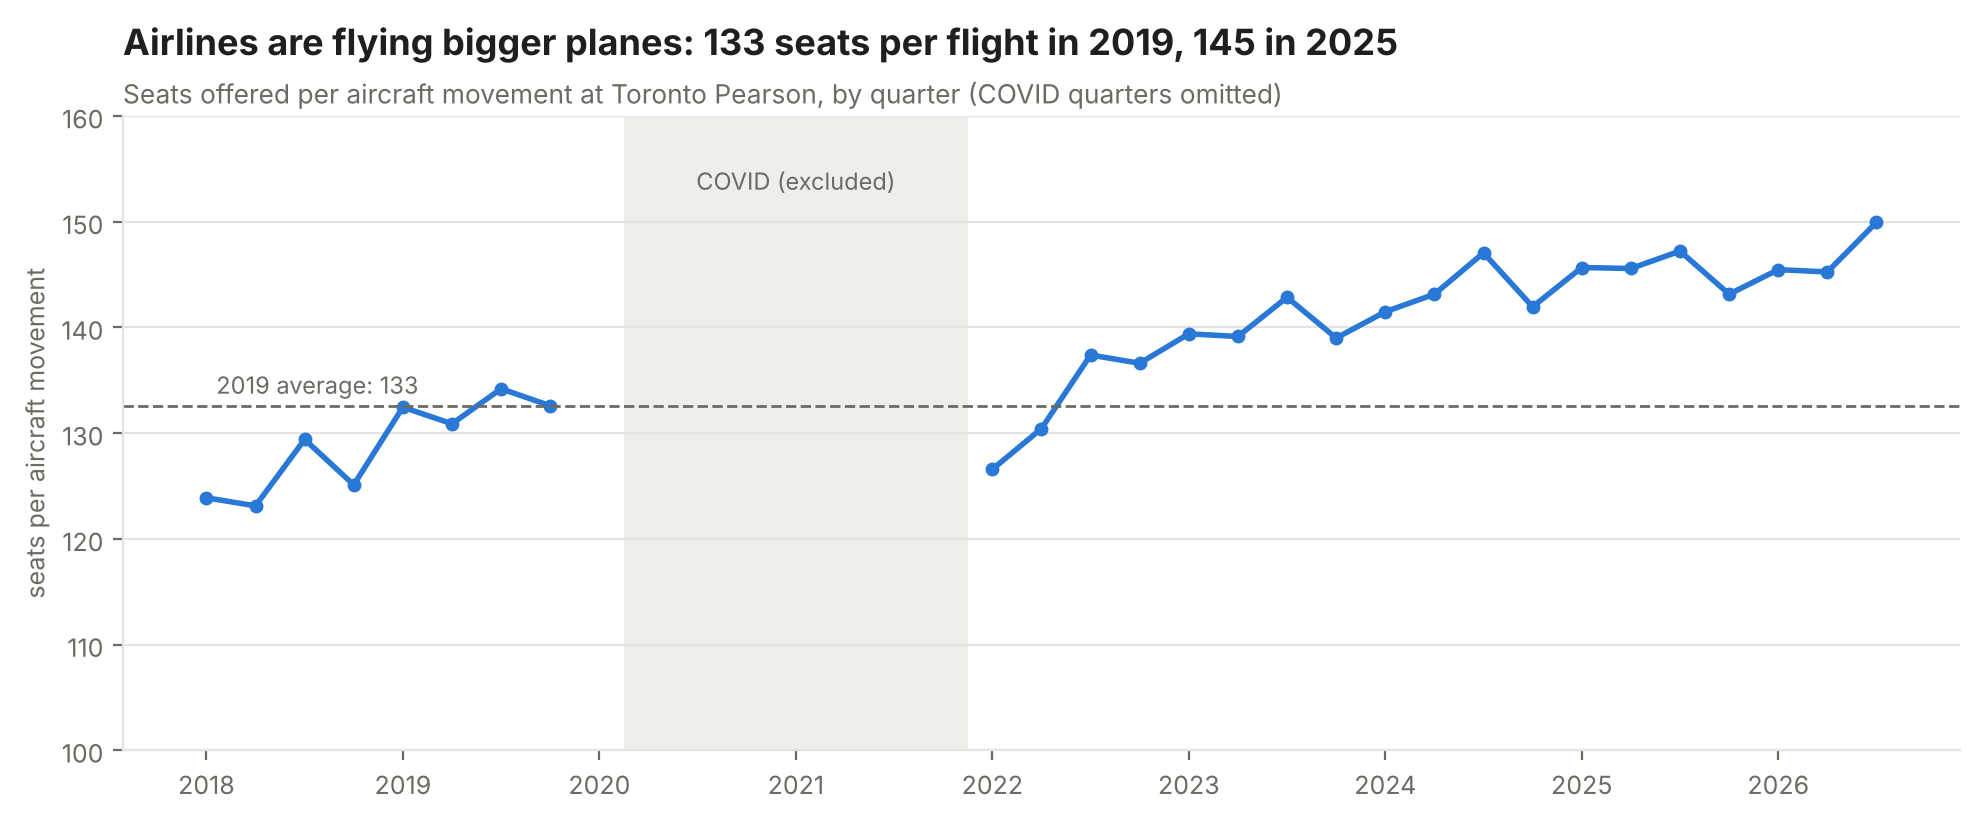

In [11]:
fig, ax = plt.subplots(figsize=(10, 4.2))
s = q.seats_per_movement.where(~q.covid_period)
ax.plot(idx, s, color=BLUE, lw=2, marker='o', ms=4)
ax.set_ylim(100, 160); covid_band(ax, x)
ax.set_xticks(ticks); ax.set_xticklabels([x[i][:4] for i in ticks])
ax.set_ylabel('seats per aircraft movement', color=MUTED, fontsize=9)
b19 = q.loc[q.year == 2019, 'seats_per_movement'].mean(); b25 = q.loc[q.year == 2025, 'seats_per_movement'].mean()
ax.axhline(b19, color=MUTED, lw=1, ls='--'); ax.text(0.2, b19 + 1.2, f'2019 average: {b19:.0f}', fontsize=8.5, color=MUTED)
style(ax, f'Airlines are flying bigger planes: {b19:.0f} seats per flight in 2019, {b25:.0f} in 2025',
      'Seats offered per aircraft movement at Toronto Pearson, by quarter (COVID quarters omitted)')
plt.tight_layout(); plt.savefig(FIG / 'phase2_seats_per_movement.png', dpi=160); plt.show()

**Reading it:** more seats per flight means passengers can grow faster than flights. Since landing fees are charged by aircraft weight and terminal charges by seat, upgauging also lifts aeronautical revenue without more movements.

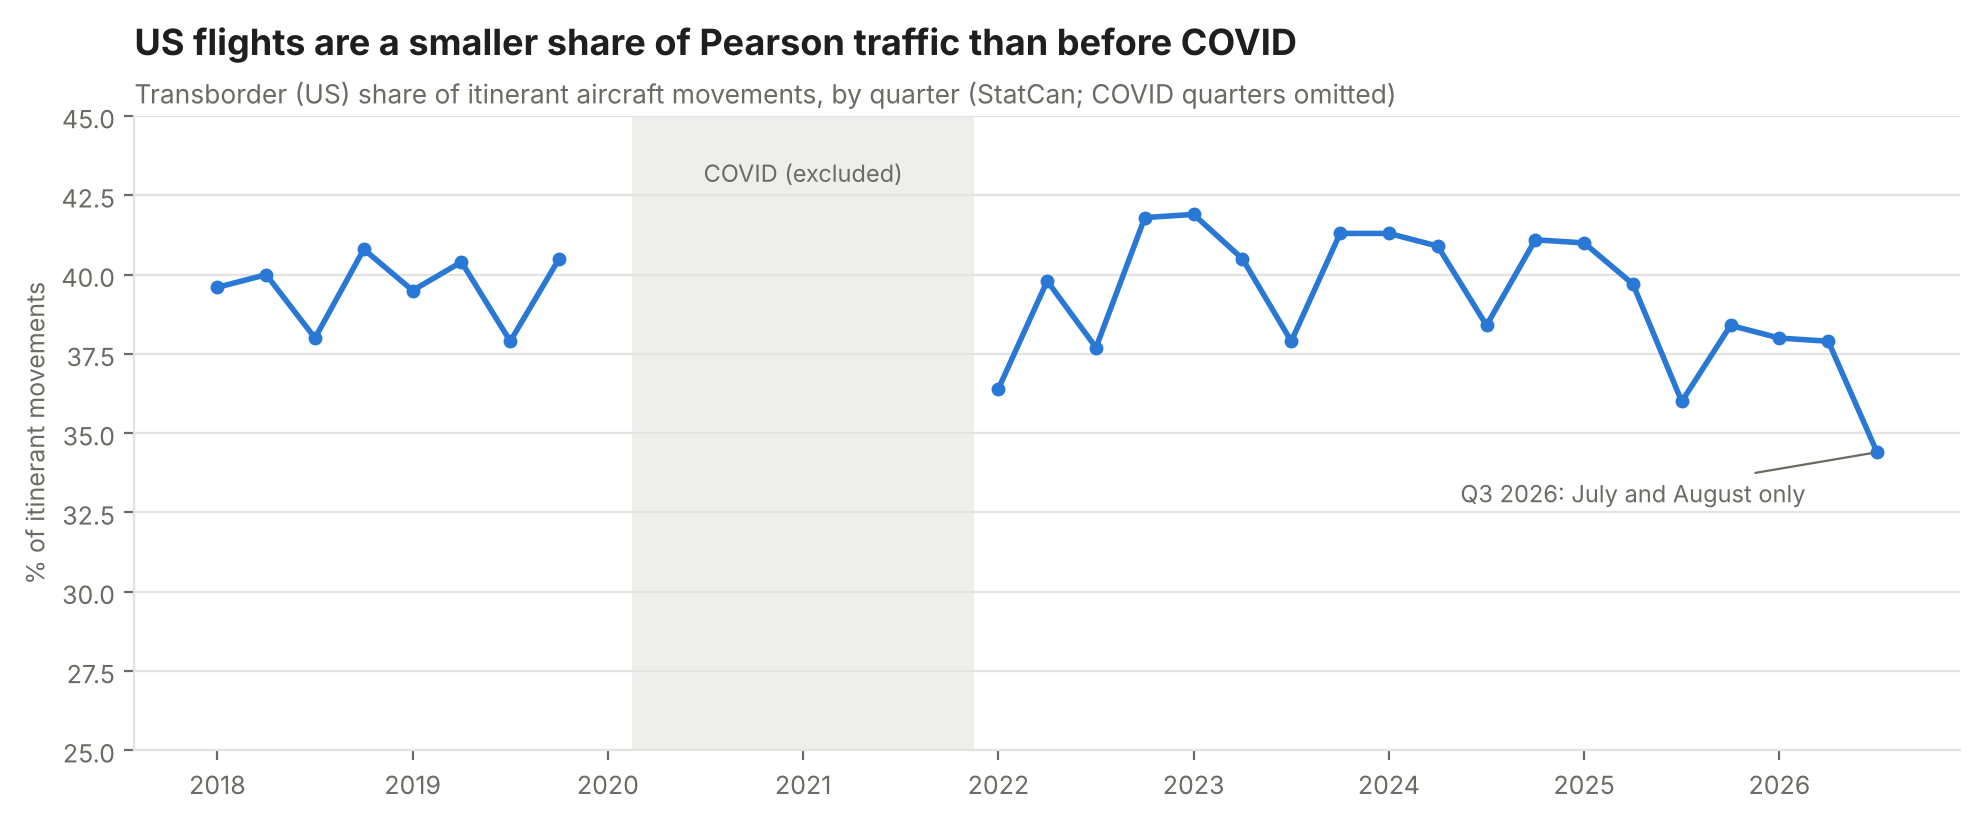

In [12]:
fig, ax = plt.subplots(figsize=(10, 4.2))
t = q.transborder_share_pct.where(~q.covid_period)
ax.plot(idx, t, color=BLUE, lw=2, marker='o', ms=4)
ax.set_ylim(25, 45); covid_band(ax, x)
ax.set_xticks(ticks); ax.set_xticklabels([x[i][:4] for i in ticks])
ax.set_ylabel('% of itinerant movements', color=MUTED, fontsize=9)
ax.annotate('Q3 2026: July and August only', (len(x)-1, t.iloc[-1]), xytext=(-150, -18), textcoords='offset points',
            fontsize=8.5, color=MUTED, arrowprops=dict(arrowstyle='-', color=MUTED, lw=0.8))
style(ax, 'US flights are a smaller share of Pearson traffic than before COVID',
      'Transborder (US) share of itinerant aircraft movements, by quarter (StatCan; COVID quarters omitted)')
plt.tight_layout(); plt.savefig(FIG / 'phase2_transborder_share.png', dpi=160); plt.show()

**Reading it:** about 40% of movements were US flights in 2018–2019 and recent quarters run 34–38%, with Q3 the seasonal low. Phase 4 puts a revenue-at-risk range on this.

## 8. Export the Supabase-ready table

Only the columns the SQL model needs, in a fixed order (a full working dataframe has extra columns that break imports).

In [13]:
EXPORT = ['period','year','quarter','period_start','covid_period','omicron_flag','ground_rent_relief_flag','cpe_available',
  # revenue ($M)
  'revenue_total','landing_fees','general_terminal','aero_revenue','concessions_rentals','parking_ground',
  'other_revenue','commercial_revenue','aif_revenue',
  # costs and results ($M)
  'ground_rent','pilt','goods_services','salaries','opex_before_amort','ebitda','net_income',
  # traffic
  'pax_domestic','pax_international','pax_total','enplaned_pax','movements','mtow','seats','load_factor',
  'transborder_movements','itinerant_movements','transborder_share_pct','statcan_complete_quarter',
  # credit
  'total_debt','net_debt','debt_per_epax','net_debt_per_epax','cpe','operating_covenant','debt_service_covenant',
  # rates and inflation
  'gtc_domestic_per_seat','gtc_non_domestic_per_seat','landing_per_1000kg','aif_local','aif_connecting',
  'aero_rate_index','cpi_ontario','deflator_2019',
  # per-unit KPIs
  'revenue_per_enplaned','aero_per_enplaned','commercial_per_enplaned','parking_per_enplaned','aif_per_enplaned',
  'opex_per_enplaned','aif_yield_ratio','implied_connecting_share','ground_rent_share_pct','aero_share_pct',
  'commercial_share_pct','aif_share_pct','seats_per_movement','pax_per_movement','mtow_tonnes_per_movement',
  'aero_per_tonne_mtow','opex_per_movement_k',
  'revenue_per_enplaned_real2019','aero_per_enplaned_real2019','commercial_per_enplaned_real2019',
  'aif_per_enplaned_real2019','opex_per_enplaned_real2019','aero_per_tonne_mtow_real2019','cpe_real2019']
out = q[EXPORT].copy()
num = out.select_dtypes('number').columns
out[num] = out[num].round(4)
out['period_start'] = out.period_start.dt.date
out.to_csv(PROC / 'kpi_quarterly.csv', index=False)
print(out.shape, '->', PROC / 'kpi_quarterly.csv')

(35, 75) -> /home/claude/yyz-revenue-runway/data/processed/kpi_quarterly.csv


## What Phase 2 hands to Phase 3

- `data/processed/kpi_quarterly.csv`: one row per quarter (35 rows), ready for Supabase
- `data/processed/fee_rates.csv`: every fee schedule's core rates

**Phase 3 (SQL)** adds what needs one quarter compared with another: year-over-year and vs-2019 changes (`LAG`), trailing 12-month totals (window sums) and the volume/rate revenue bridge.